In [2]:
import requests
import pandas as pd
import geopandas as gpd
import contextily as ctx
import numpy as np
from shapely.geometry import Point
import matplotlib.pyplot as plt
from rasterio.plot import show
from scipy.stats import gaussian_kde
from sklearn.cluster import DBSCAN

# **Loading Datasets**

In [3]:
ev_stations = pd.read_csv("./Datasets/ev_stations_CA.csv")

In [4]:
geometry = [Point(xy) for xy in zip(ev_stations["Longitude"], ev_stations["Latitude"])]

In [5]:
ev_stations_gdf = gpd.GeoDataFrame(ev_stations, geometry=geometry)

In [6]:
ev_stations_gdf.head()

,Name,Latitude,Longitude,Address,Town,State,Postcode,geometry
0,Fairfield Civic Center - Lot A,38.252288,-122.044230,1000 Webster Street,Fairfield,CA,94533,POINT (-122.04423 38.25229)
1,"Ionna - Oceanside, CA",33.216919,-117.271504,4760 Oceanside Blvd,Oceanside,CA,92056,POINT (-117.2715 33.21692)
2,"IONNA Rechargery - Castaic, CA",34.491076,-118.618919,31505 Castaic Rd,Castaic,CA,91384,POINT (-118.61892 34.49108)
3,BP Pulse - SFO,37.650023,-122.405881,177 S Airport Blvd,South San Francisco,CA,94080,POINT (-122.40588 37.65002)
4,Ionna,37.717485,-122.442329,2201 Alemany Blvd,San Francisco,CA,94112,POINT (-122.44233 37.71748)


In [7]:
ev_stations_gdf= ev_stations_gdf[["Name", "geometry"]]


In [8]:
ev_stations_gdf.set_crs(epsg=4326, inplace=True)

,Name,geometry
0,Fairfield Civic Center - Lot A,POINT (-122.04423 38.25229)
1,"Ionna - Oceanside, CA",POINT (-117.2715 33.21692)
2,"IONNA Rechargery - Castaic, CA",POINT (-118.61892 34.49108)
3,BP Pulse - SFO,POINT (-122.40588 37.65002)
4,Ionna,POINT (-122.44233 37.71748)
5,Smart & Final,POINT (-118.12612 34.03071)
6,Bishop Ranch 3,POINT (-121.95835 37.76496)
7,Valley Oaks Inn,POINT (-121.76428 38.69708)
8,Yosemite Charging Outpost,POINT (-120.23098 37.83844)
9,Pismo Beach Premium Outlets,POINT (-120.62884 35.13492)


In [9]:
# Loading California Roads Shapefile
roads_gdf = gpd.read_file("./Datasets/RoadFiles/tl_2024_06_prisecroads.shp")
roads_gdf= roads_gdf[["FULLNAME", "geometry"]]

In [10]:
roads_gdf.head()

,FULLNAME,geometry
0,Lincoln Byp,"LINESTRING (-121.29951 38.85805, -121.29952 38..."
1,I- 5 Local Byp,"LINESTRING (-117.24024 32.92973, -117.24024 32..."
2,Roseville Byp,"LINESTRING (-121.3003 38.81831, -121.30032 38...."
3,Roseville Byp,"LINESTRING (-121.30017 38.83067, -121.30017 38..."
4,Lincoln Byp,"LINESTRING (-121.30007 38.83959, -121.30006 38..."


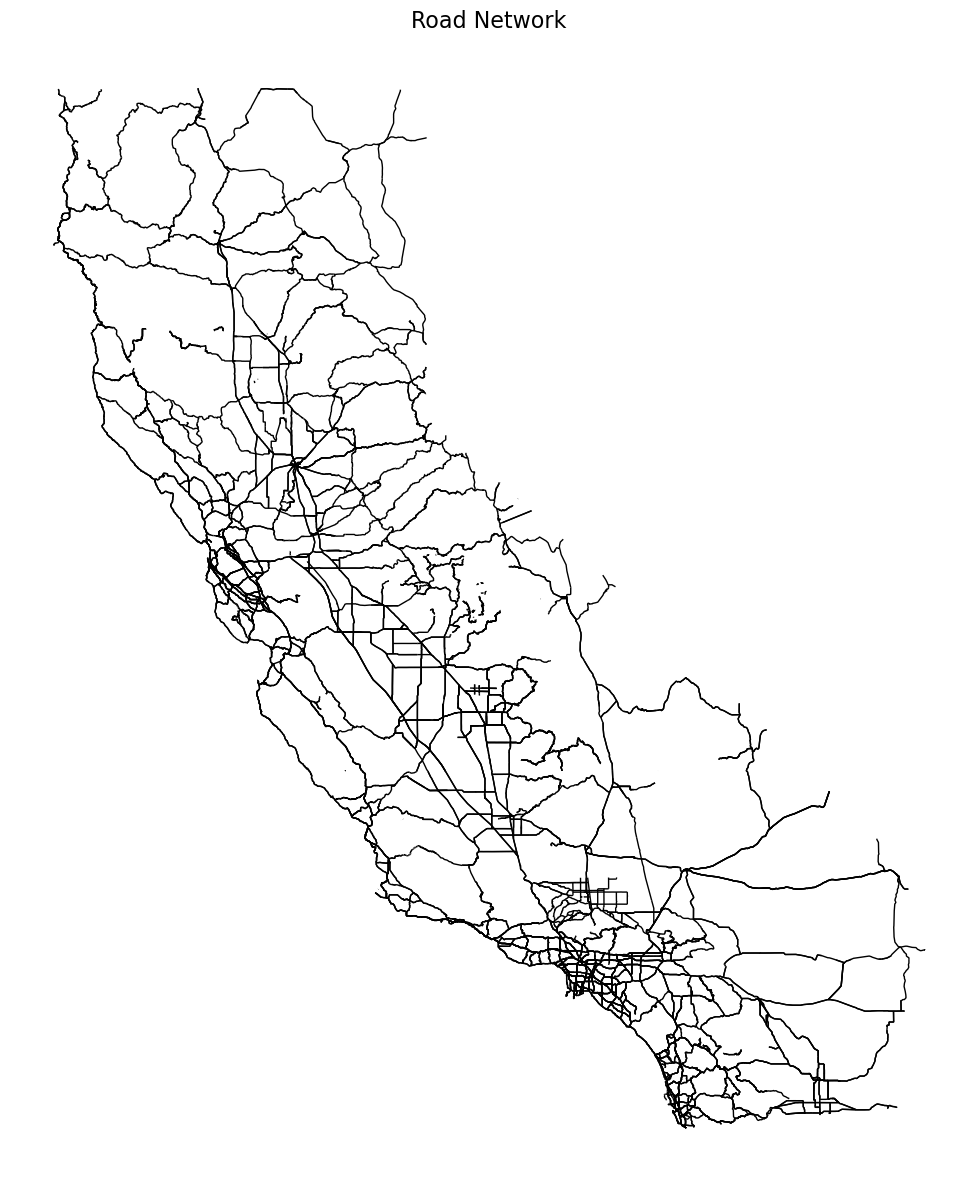

In [11]:

#plotting roads of california
fig, ax = plt.subplots(figsize=(12, 12))
roads_gdf.plot(ax=ax, color='black', linewidth=1)

ax.set_title("Road Network", fontsize=16)
ax.axis('off')

plt.tight_layout()
plt.show()


In [12]:
#Loading Traffic Data of California
traffic_gdf = gpd.read_file("./Datasets/TrafficData/Annual_Average_Daily_Traffic.shp")

In [13]:
traffic_gdf = traffic_gdf[["LOCATION_D", "AHEAD_AADT","geometry"]]

In [14]:
traffic_gdf.head()

,LOCATION_D,AHEAD_AADT,geometry
0,BEG INDEP ALIGN LT LNS,46000.0,POINT (-117.225 32.89966)
1,"SAN DIEGO, SORRENTO VALLEY ROAD",40000.0,POINT (-117.22467 32.90081)
2,"SAN DIEGO, NORTH JCT RTE 805",60000.0,POINT (-117.22482 32.9045)
3,"R31.155 EQUATES R31.188, END INDEP ALIGN",None,POINT (-117.22822 32.91065)
4,BEG INDEP ALIGN LT LNS,133900.0,POINT (-117.97515 33.85399)


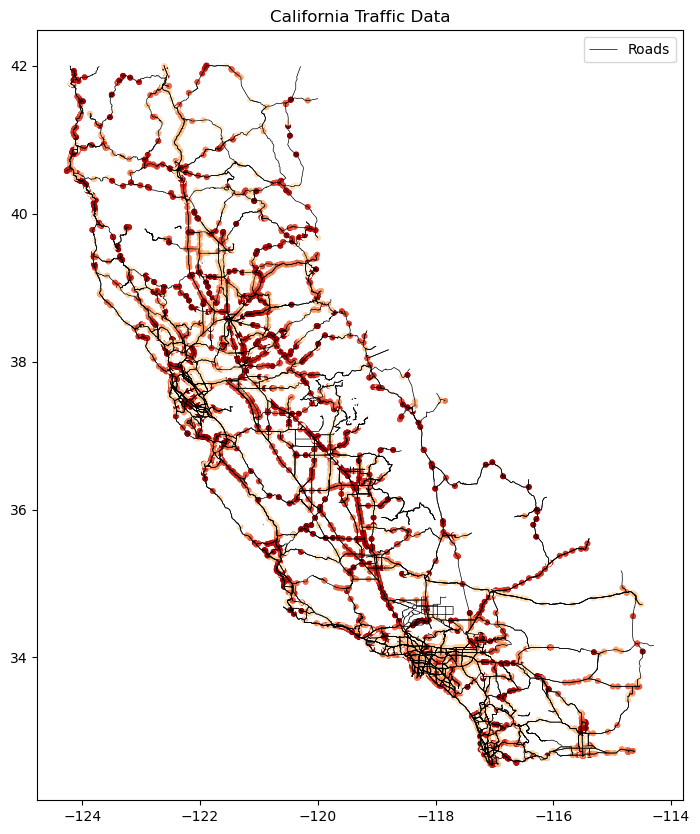

In [15]:
traffic_gdf = traffic_gdf.to_crs(epsg=4326)
roads_gdf= roads_gdf.to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(10, 10))
traffic_gdf.plot(column="AHEAD_AADT", cmap="OrRd", ax=ax, markersize=10, legend=True)
roads_gdf.plot(ax=ax, color='black', linewidth=0.5, label="Roads")

plt.title("California Traffic Data")
plt.legend()
plt.show()


**Log transformed traffic volume**

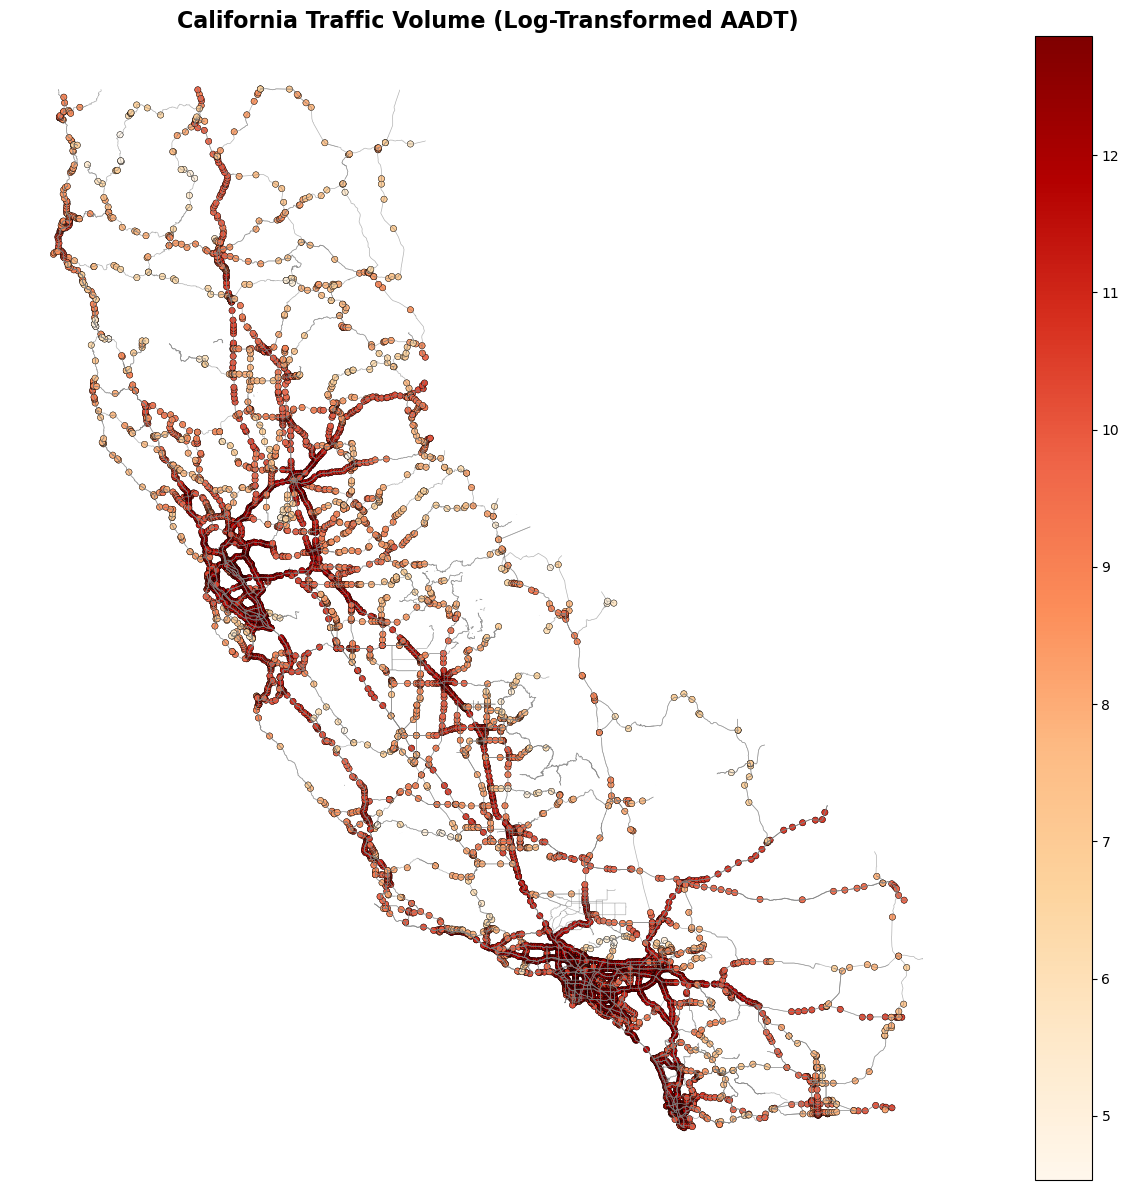

In [16]:
traffic_gdf["AHEAD_AADT"] = pd.to_numeric(traffic_gdf["AHEAD_AADT"], errors='coerce')
traffic_gdf["AADT_LOG"] = np.log1p(traffic_gdf["AHEAD_AADT"])

traffic_gdf_3857 = traffic_gdf.to_crs(epsg=3857)
roads_gdf_3857 = roads_gdf.to_crs(epsg=3857)

# Plotting
fig, ax = plt.subplots(figsize=(14, 12))

# plotting Roads
roads_gdf_3857.plot(ax=ax, color='gray', linewidth=0.5, alpha=0.6, label="Roads")

# plotting Traffic points with log-transformed color scale
traffic_gdf_3857.plot(
    column="AADT_LOG",
    cmap="OrRd",
    ax=ax,
    markersize=20,
    legend=True,
    alpha=0.8,
    edgecolor='k',
    linewidth=0.3
)

# Title & layout
ax.set_title("California Traffic Volume (Log-Transformed AADT)", fontsize=16, fontweight='bold')
ax.axis("off")

plt.tight_layout()
plt.show()


In [17]:
# loading california census tracts
california_tracts_gdf = gpd.read_file("./Datasets/tractData/tl_2019_06_tract.shp")

In [18]:
california_tracts_gdf.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,06,037,139301,06037139301,1393.01,Census Tract 1393.01,G5020,S,2865657,0,+34.1781538,-118.5581265,"POLYGON ((-118.5715 34.17758, -118.57148 34.17..."
1,06,037,139302,06037139302,1393.02,Census Tract 1393.02,G5020,S,338289,0,+34.1767230,-118.5383655,"POLYGON ((-118.54073 34.1802, -118.5407 34.180..."
2,06,037,139502,06037139502,1395.02,Census Tract 1395.02,G5020,S,1047548,0,+34.1628402,-118.5263110,"POLYGON ((-118.53224 34.16201, -118.53177 34.1..."
3,06,037,139600,06037139600,1396,Census Tract 1396,G5020,S,2477482,0,+34.1640599,-118.5101001,"POLYGON ((-118.51858 34.15858, -118.51858 34.1..."
4,06,037,139701,06037139701,1397.01,Census Tract 1397.01,G5020,S,3396396,2411,+34.1574290,-118.4954117,"POLYGON ((-118.5098 34.15691, -118.50848 34.15..."


In [19]:
california_tracts_gdf = california_tracts_gdf[["GEOID", "ALAND", "geometry"]]

In [20]:
california_tracts_gdf.head()

,GEOID,ALAND,geometry
0,06037139301,2865657,"POLYGON ((-118.5715 34.17758, -118.57148 34.17..."
1,06037139302,338289,"POLYGON ((-118.54073 34.1802, -118.5407 34.180..."
2,06037139502,1047548,"POLYGON ((-118.53224 34.16201, -118.53177 34.1..."
3,06037139600,2477482,"POLYGON ((-118.51858 34.15858, -118.51858 34.1..."
4,06037139701,3396396,"POLYGON ((-118.5098 34.15691, -118.50848 34.15..."


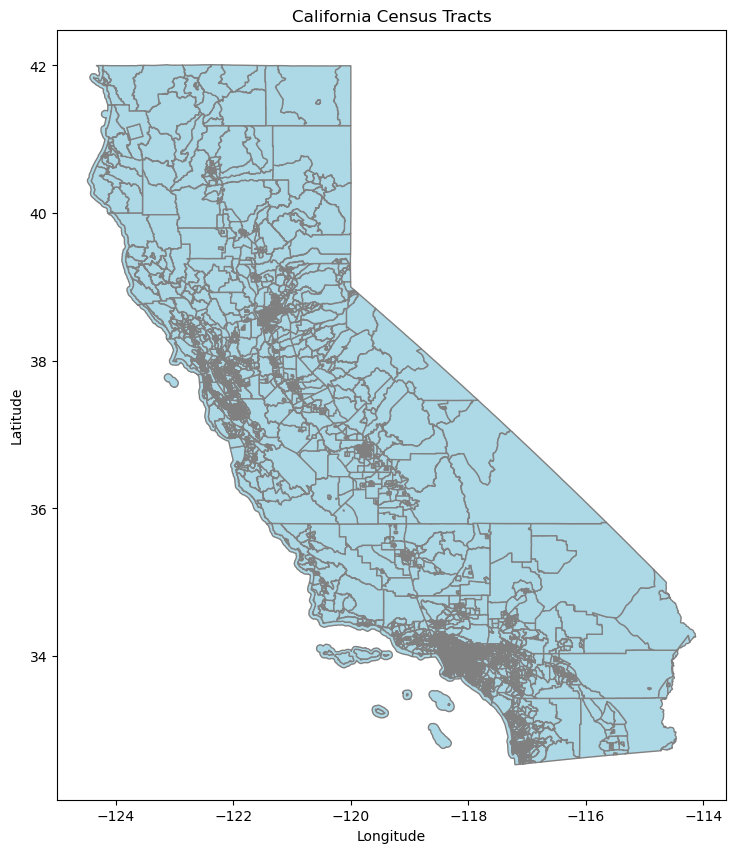

In [21]:
#plotting tracts
california_tracts_gdf.plot(figsize=(10, 10), edgecolor="gray", facecolor="lightblue")
plt.title("California Census Tracts")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [22]:
california_tracts_gdf.head()

,GEOID,ALAND,geometry
0,06037139301,2865657,"POLYGON ((-118.5715 34.17758, -118.57148 34.17..."
1,06037139302,338289,"POLYGON ((-118.54073 34.1802, -118.5407 34.180..."
2,06037139502,1047548,"POLYGON ((-118.53224 34.16201, -118.53177 34.1..."
3,06037139600,2477482,"POLYGON ((-118.51858 34.15858, -118.51858 34.1..."
4,06037139701,3396396,"POLYGON ((-118.5098 34.15691, -118.50848 34.15..."


In [23]:
#loading population data
population_df = pd.read_csv("./Datasets/PopData/populationData.csv", usecols=[0, 1, 2])

In [24]:
population_df.head(10)

,GEO_ID,NAME,B01003_001E
0,Geography,Geographic Area Name,Estimate!!Total
1,0400000US06,California,39242785
2,1400000US06001400100,Census Tract 4001; Alameda County; California,3094
3,1400000US06001400200,Census Tract 4002; Alameda County; California,2093
4,1400000US06001400300,Census Tract 4003; Alameda County; California,5727
5,1400000US06001400400,Census Tract 4004; Alameda County; California,4395
6,1400000US06001400500,Census Tract 4005; Alameda County; California,3822
7,1400000US06001400600,Census Tract 4006; Alameda County; California,1957
8,1400000US06001400700,Census Tract 4007; Alameda County; California,4404
9,1400000US06001400800,Census Tract 4008; Alameda County; California,4583


# **Merging Population data with California Census tracts dataset based on Geoid**

In [25]:
#Clean GEOID in population dataframe
population_df['GEOID'] = population_df['GEO_ID'].str.replace('1400000US', '', regex=False)
population_df = population_df[population_df['GEOID'].str.len() == 11]

#Merging california tracts with population data
merged_gdf = california_tracts_gdf.merge(population_df, on='GEOID', how='left')

#Converting ALand and population to numeric
merged_gdf['ALAND'] = pd.to_numeric(merged_gdf['ALAND'], errors='coerce')
merged_gdf['B01003_001E'] = pd.to_numeric(merged_gdf['B01003_001E'], errors='coerce')

#Drop rows with missing data
merged_gdf = merged_gdf.dropna(subset=['ALAND', 'B01003_001E'])
merged_gdf = merged_gdf[merged_gdf['ALAND'] > 0]

#Calculate population density
merged_gdf['area_km2'] = merged_gdf['ALAND'] / 1e6
merged_gdf['pop_density'] = merged_gdf['B01003_001E'] / merged_gdf['area_km2']


In [26]:
merged_gdf.head()

,GEOID,ALAND,geometry,GEO_ID,NAME,B01003_001E,area_km2,pop_density
0,06037139301,2865657,"POLYGON ((-118.5715 34.17758, -118.57148 34.17...",1400000US06037139301,Census Tract 1393.01; Los Angeles County; Cali...,4137.0,2.865657,1443.648001
1,06037139302,338289,"POLYGON ((-118.54073 34.1802, -118.5407 34.180...",1400000US06037139302,Census Tract 1393.02; Los Angeles County; Cali...,5001.0,0.338289,14783.217899
2,06037139502,1047548,"POLYGON ((-118.53224 34.16201, -118.53177 34.1...",1400000US06037139502,Census Tract 1395.02; Los Angeles County; Cali...,3315.0,1.047548,3164.532795
3,06037139600,2477482,"POLYGON ((-118.51858 34.15858, -118.51858 34.1...",1400000US06037139600,Census Tract 1396; Los Angeles County; California,5164.0,2.477482,2084.374377
4,06037139701,3396396,"POLYGON ((-118.5098 34.15691, -118.50848 34.15...",1400000US06037139701,Census Tract 1397.01; Los Angeles County; Cali...,5635.0,3.396396,1659.111599


# **Log based Population density by census tract**

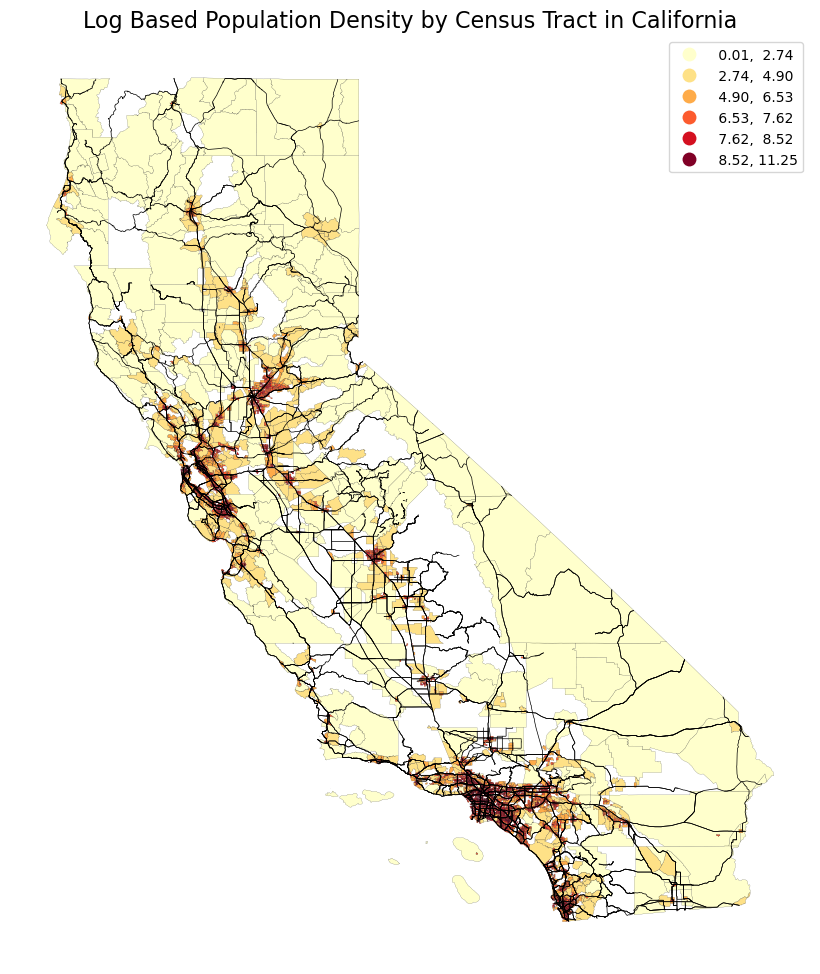

In [27]:
filtered_gdf = merged_gdf[merged_gdf['pop_density'] > 0]
filtered_gdf = filtered_gdf.copy()
filtered_gdf['log_pop_density'] = np.log1p(filtered_gdf['pop_density'])

roads_gdf = roads_gdf.to_crs(epsg=3857)
filtered_gdf= filtered_gdf.to_crs(epsg=3857)

#plotting Log based population density
fig, ax = plt.subplots(figsize=(12, 10))
filtered_gdf.plot(
    column='log_pop_density',
    cmap='YlOrRd',
    legend=True,
    scheme='natural_breaks',
    k=6,
    ax=ax,
    edgecolor='black',
    linewidth=0.1
)
roads_gdf.plot(ax=ax, color='black', linewidth=0.5, label="Roads")

ax.set_title("Log Based Population Density by Census Tract in California", fontsize=16)
ax.axis('off')
plt.tight_layout()
plt.show()

In [28]:
filtered_gdf.head()

,GEOID,ALAND,geometry,GEO_ID,NAME,B01003_001E,area_km2,pop_density,log_pop_density
0,06037139301,2865657,"POLYGON ((-13199318.557 4052671.544, -13199317...",1400000US06037139301,Census Tract 1393.01; Los Angeles County; Cali...,4137.0,2.865657,1443.648001,7.275621
1,06037139302,338289,"POLYGON ((-13195894.147 4053023.552, -13195890...",1400000US06037139302,Census Tract 1393.02; Los Angeles County; Cali...,5001.0,0.338289,14783.217899,9.601316
2,06037139502,1047548,"POLYGON ((-13194949.156 4050576.811, -13194896...",1400000US06037139502,Census Tract 1395.02; Los Angeles County; Cali...,3315.0,1.047548,3164.532795,8.060077
3,06037139600,2477482,"POLYGON ((-13193428.309 4050114.836, -13193428...",1400000US06037139600,Census Tract 1396; Los Angeles County; California,5164.0,2.477482,2084.374377,7.642704
4,06037139701,3396396,"POLYGON ((-13192450.59 4049890.446, -13192304....",1400000US06037139701,Census Tract 1397.01; Los Angeles County; Cali...,5635.0,3.396396,1659.111599,7.414640


In [29]:
ev_stations_gdf = ev_stations_gdf.to_crs(epsg=3857)

# **plotting all layers: Existing EV stations, Roads, Traffic, population density**"

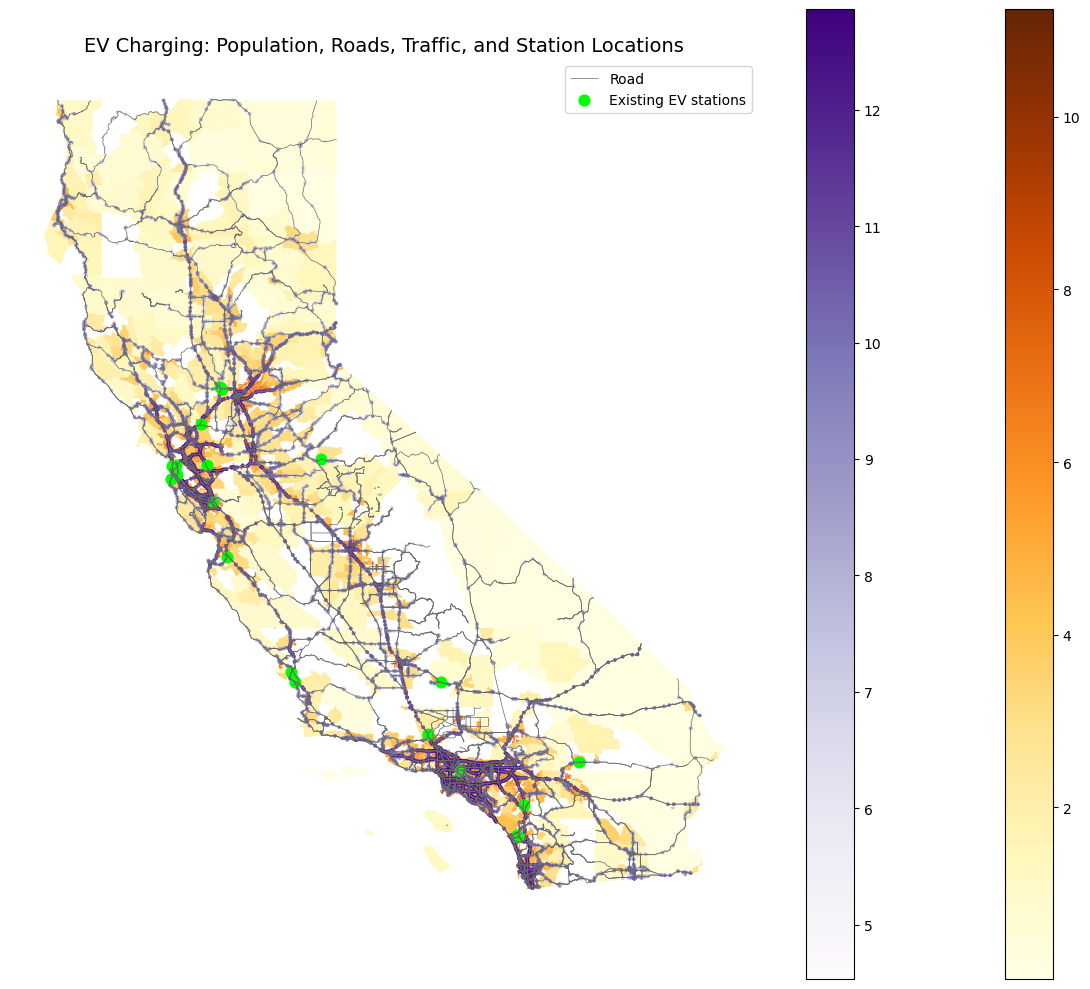

In [30]:
roads_gdf = roads_gdf.to_crs(epsg=3857)
traffic_gdf_3857 = traffic_gdf.to_crs(epsg=3857)
ev_stations_gdf = ev_stations_gdf.to_crs(epsg=3857)

#plotting all Population,Roads, Traffic and EV charging stations
fig, ax = plt.subplots(figsize=(12, 10))
filtered_gdf.plot(column='log_pop_density', cmap='YlOrBr', ax=ax, legend=True)
roads_gdf.plot(ax=ax, color='dimgray', linewidth=0.5, label= "Road")
traffic_gdf_3857.plot(ax=ax, column='AADT_LOG', cmap='Purples', alpha=0.6,markersize=3,legend=True)
ev_stations_gdf.plot(ax=ax, color='lime', markersize=60, label="Existing EV stations")
ax.set_title("EV Charging: Population, Roads, Traffic, and Station Locations", fontsize=14)
ax.axis('off')
ax.legend()
plt.tight_layout()
plt.show()


# **KDE Demand Heatmap: Population + Traffic for EV Charging**

[[1.31252581e-198 3.08549487e-197 7.16743604e-196 ... 2.01620812e-014
  1.91402719e-014 1.84200795e-014]
 [1.54853079e-197 3.60735475e-196 8.30385743e-195 ... 2.05460288e-014
  1.97882209e-014 1.93117662e-014]
 [1.81127006e-196 4.18123187e-195 9.53778035e-194 ... 2.12196905e-014
  2.07227489e-014 2.04827789e-014]
 ...
 [2.68992993e-013 2.75050744e-013 2.78889653e-013 ... 1.90437902e-256
  5.01471496e-258 1.30485164e-259]
 [2.65796866e-013 2.70220510e-013 2.72405259e-013 ... 1.14835050e-257
  2.99653504e-259 7.72656175e-261]
 [2.61261386e-013 2.64061838e-013 2.64639476e-013 ... 6.86510072e-259
  1.77518592e-260 4.53589295e-262]]


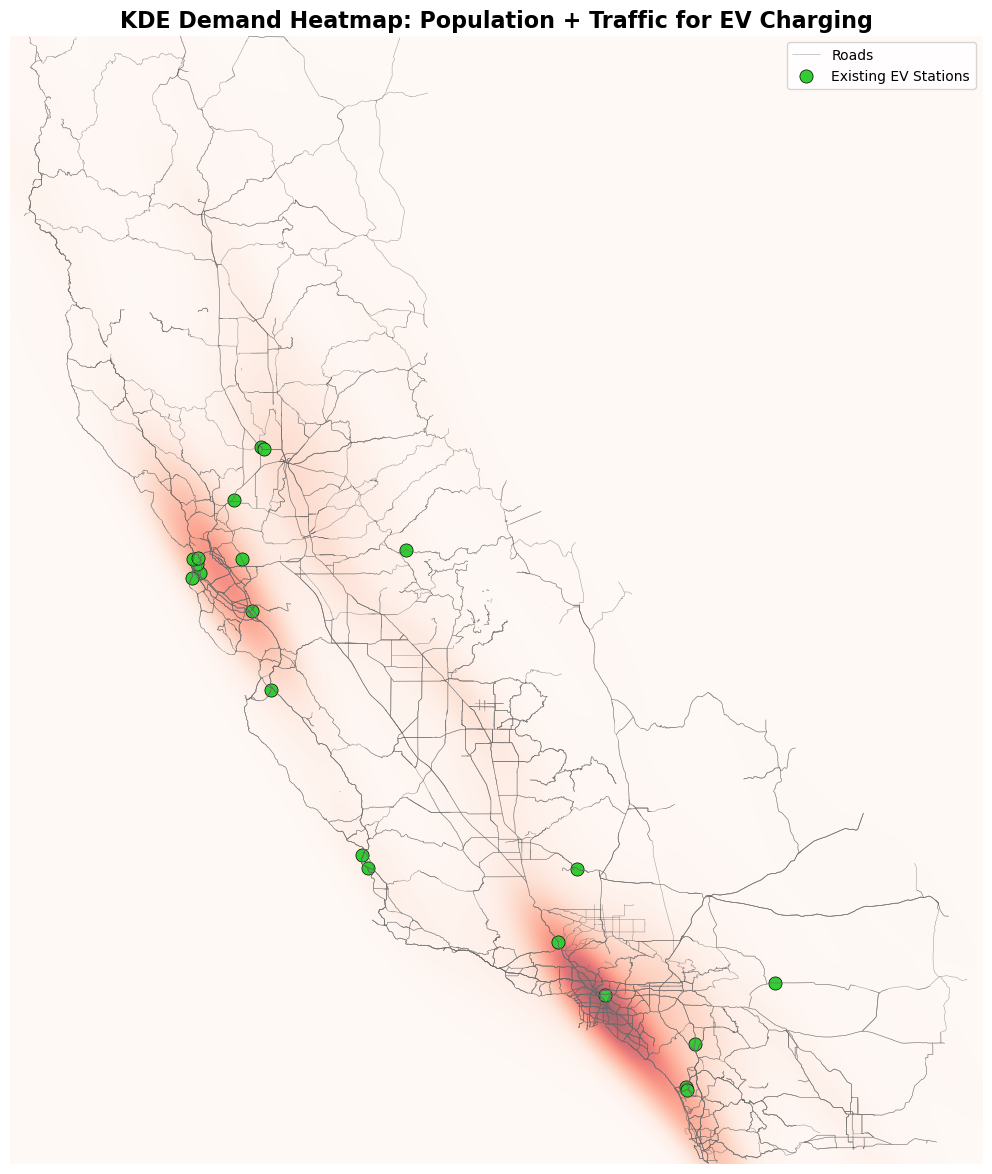

In [31]:
# 1) Convert to same CRS (Web Mercator)
roads_gdf = roads_gdf.to_crs(epsg=3857)
traffic_gdf_3857 = traffic_gdf.to_crs(epsg=3857)
ev_stations_gdf = ev_stations_gdf.to_crs(epsg=3857)
filtered_gdf = filtered_gdf.to_crs(epsg=3857)

# 2) Prepare grid for KDE
bounds = filtered_gdf.total_bounds
x_min, y_min, x_max, y_max = bounds
n_cells = 500  # resolution

x_grid = np.linspace(x_min, x_max, n_cells)
y_grid = np.linspace(y_min, y_max, n_cells)
xv, yv = np.meshgrid(x_grid, y_grid)
grid_points = np.vstack([xv.ravel(), yv.ravel()])

# 3) Combine KDE input: Population + Traffic

# Population data
p_valid = ~np.isnan(filtered_gdf['log_pop_density'].values)
p_centroids = filtered_gdf.geometry.centroid[p_valid]
p_wts = filtered_gdf['log_pop_density'].values[p_valid]
p_xy = np.vstack([p_centroids.x.values, p_centroids.y.values])

# Traffic data
t_valid = ~np.isnan(traffic_gdf_3857['AADT_LOG'].values)
t_points = traffic_gdf_3857.geometry[t_valid]
t_wts = traffic_gdf_3857['AADT_LOG'].values[t_valid]
t_xy = np.vstack([t_points.x.values, t_points.y.values])

# Combine population + traffic
d_xy = np.hstack([p_xy, t_xy])
d_wts = np.concatenate([p_wts, t_wts])
d_wts = d_wts / d_wts.max()  # normalize

# 4) KDE
d_kde = gaussian_kde(d_xy, bw_method=0.2, weights=d_wts)
d_vals = d_kde(grid_points).reshape(n_cells, n_cells)
print(d_vals)
# 5) Plotting KDE Heatmap
fig, ax = plt.subplots(figsize=(14, 12))

# KDE heatmap
ax.imshow(
    d_vals,
    origin="lower",
    extent=(x_min, x_max, y_min, y_max),
    cmap="Reds",
    alpha=0.6,
)

# Overlay roads
roads_gdf.plot(ax=ax, color='dimgray', linewidth=0.4, label='Roads', alpha=0.6)

# EV Stations
ev_stations_gdf.plot(ax=ax, color='limegreen', markersize=90, marker='o', edgecolor='black', linewidth=0.5, label='Existing EV Stations')

ax.set_title("KDE Demand Heatmap: Population + Traffic for EV Charging", fontsize=16, fontweight='bold')
ax.axis('off')
ax.legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

# **EV Charging Station Location Prediction using KDE + DBSCAN**

Number of clusters: 4
Number of noise points: 0

predicted EV stations:

                            geometry     kde_score
0  POINT (-13121117.647 4009575.583)  1.423153e-11
1  POINT (-13321291.348 4385042.505)  3.285731e-12
2  POINT (-13601499.005 4536397.408)  1.083616e-11
3  POINT (-13507382.153 4624911.142)  3.935918e-12

Sorted predicted EV stations:

                            geometry     kde_score
0  POINT (-13121117.647 4009575.583)  1.423153e-11
2  POINT (-13601499.005 4536397.408)  1.083616e-11
3  POINT (-13507382.153 4624911.142)  3.935918e-12
1  POINT (-13321291.348 4385042.505)  3.285731e-12


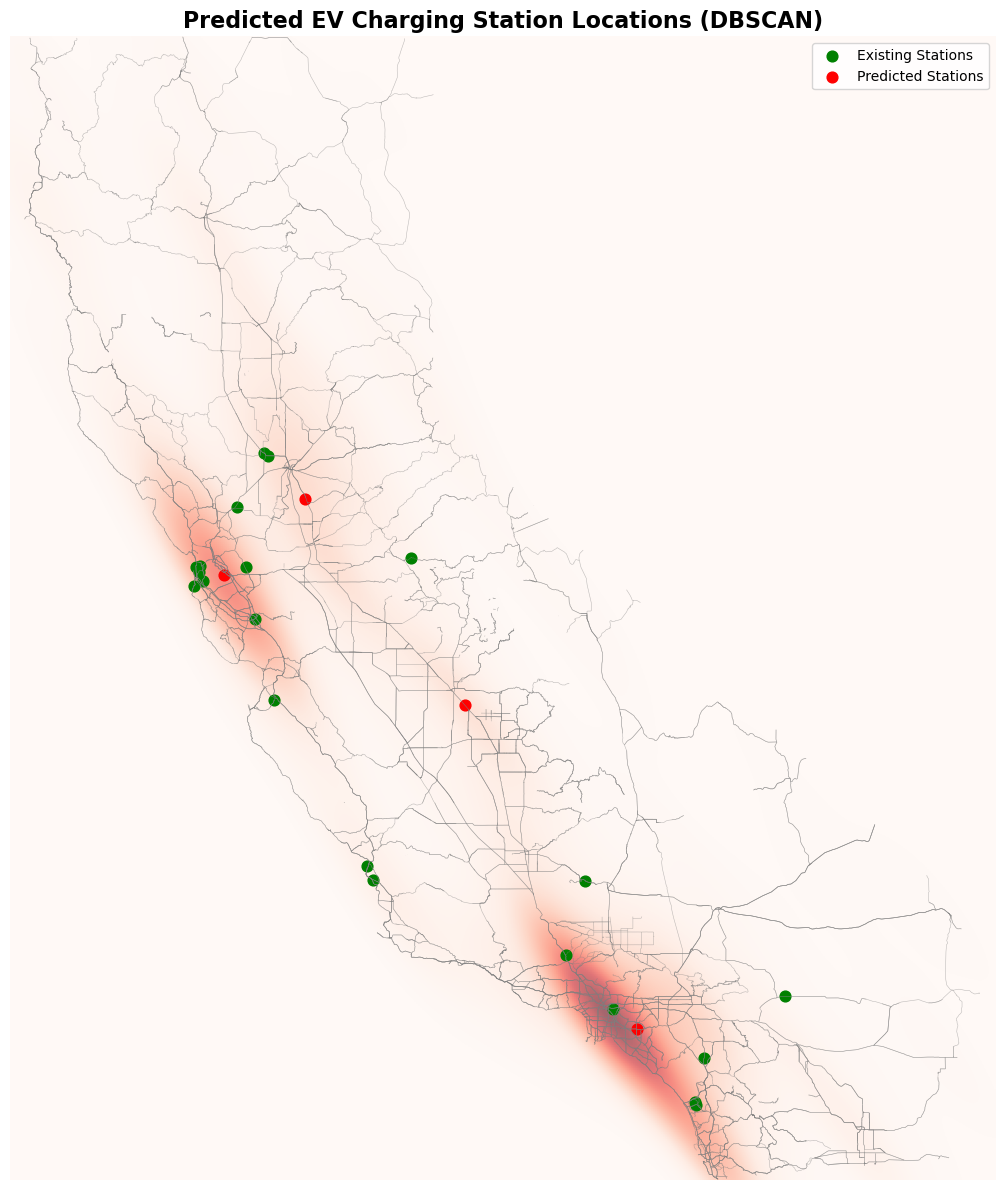

In [32]:
from shapely.ops import unary_union

#1.) Extracting high-demand points from KDE
# Choose threshold for high demand
threshold = np.percentile(d_vals, 95)  # Top 5% KDE values
# Get grid cell indices above threshold
high_kde_indices = np.argwhere(d_vals >= threshold)
# Convert to coordinates
high_kde_points = [Point(x_grid[x], y_grid[y]) for y, x in high_kde_indices]
# GeoDataFrame of high KDE points

high_kde_gdf = gpd.GeoDataFrame(geometry=high_kde_points, crs="EPSG:3857")

#2.) Run DBSCAN on high-demand coordinates
# Extract coordinates
coords = np.array([[pt.x, pt.y] for pt in high_kde_gdf.geometry])
# Run DBSCAN
db = DBSCAN(eps=2700, min_samples=3).fit(coords)
# Assign cluster labels
high_kde_gdf['cluster'] = db.labels_

#printing number of clusters
n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f"Number of clusters: {n_clusters}")
n_noise = list(db.labels_).count(-1)
print(f"Number of noise points: {n_noise}")

#3.) Create cluster centroids (predicted EV locations)
# Keep only clustered points (exclude noise)
clusters_only = high_kde_gdf[high_kde_gdf['cluster'] != -1]
# Create centroids of clusters
if not clusters_only.empty:
    predicted_clusters = clusters_only.dissolve(by='cluster', as_index=False).centroid
    predicted_ev_stations_gdf = gpd.GeoDataFrame(geometry=predicted_clusters, crs="EPSG:3857")

#4.) Score each predicted point using KDE
# Score with original KDE function
predicted_ev_stations_gdf['kde_score'] = d_kde(np.vstack([predicted_ev_stations_gdf.geometry.x, predicted_ev_stations_gdf.geometry.y]))
print(f"\npredicted EV stations:\n\n{predicted_ev_stations_gdf.head(5)}")

# Sort by score (most important locations first)
predicted_ev_stations_gdf = predicted_ev_stations_gdf.sort_values(by='kde_score', ascending=False)
print(f"\nSorted predicted EV stations:\n\n{predicted_ev_stations_gdf.head(5)}")

#5.) Filter out predicted points too close to existing EV stations
# Create buffer around existing EV stations (500 meters)
buffer = ev_stations_gdf.buffer(500)
existing_zone = unary_union(buffer)
# Keep only predictions not within existing zones
filtered_predicted_ev_stations = predicted_ev_stations_gdf[~predicted_ev_stations_gdf.geometry.within(existing_zone)]

#6.) Visualize results
fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(
    d_vals,
    origin="lower",
    extent=(x_min, x_max, y_min, y_max),
    cmap="Reds",
    alpha=0.6,
)

roads_gdf.plot(ax=ax, color='gray', linewidth=0.4, alpha=0.5)
ev_stations_gdf.plot(ax=ax, color='green', label='Existing Stations', markersize=60)
filtered_predicted_ev_stations.plot(ax=ax, color='red', label='Predicted Stations', markersize=60)
ax.set_title("Predicted EV Charging Station Locations (DBSCAN)", fontsize=16, fontweight='bold')
ax.axis('off')
ax.legend()
plt.tight_layout()
plt.show()


# **Final Visualization: Population, Roads, Traffic, Existing and Predicted EV Charging Stations**

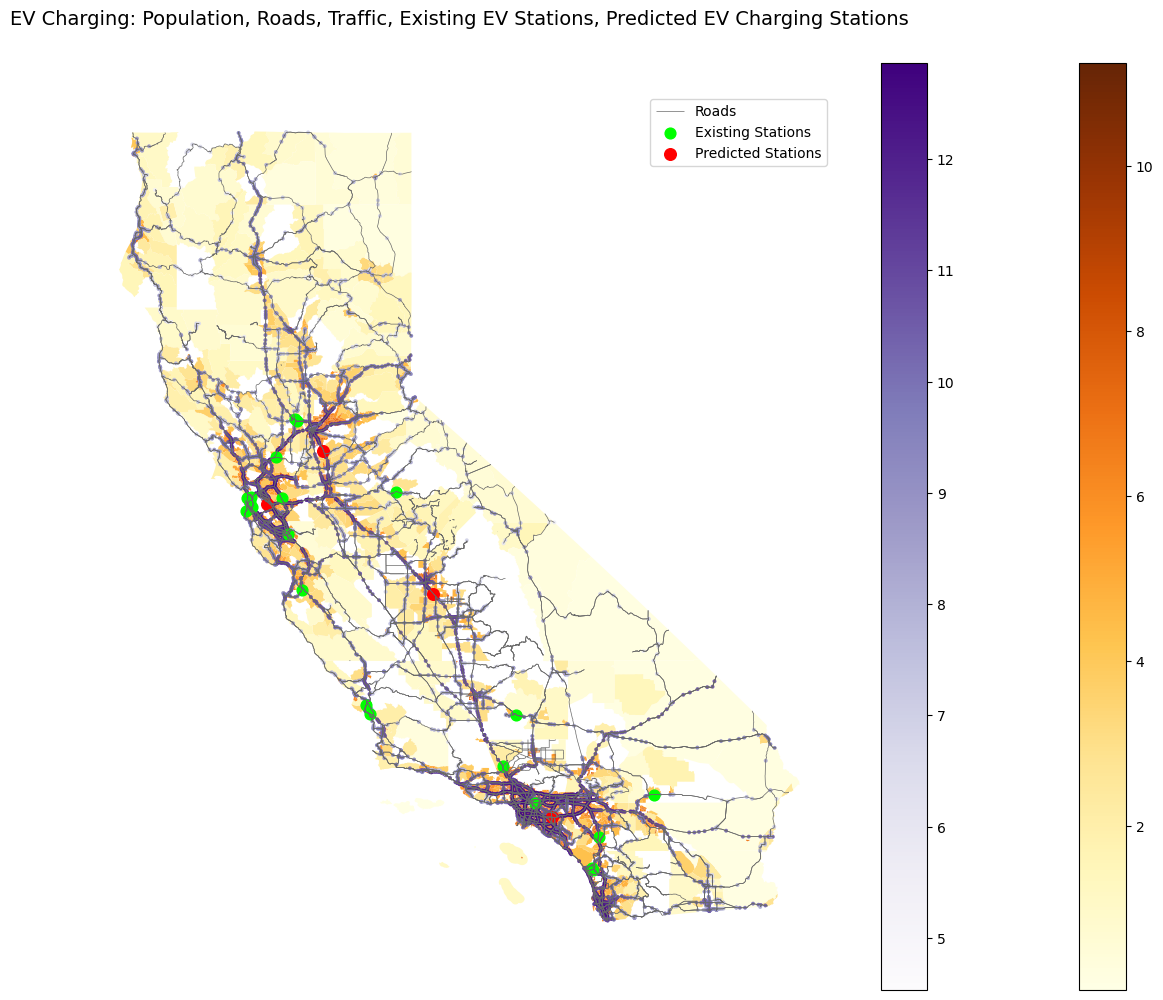

In [34]:
roads_gdf = roads_gdf.to_crs(epsg=3857)
traffic_gdf_3857 = traffic_gdf.to_crs(epsg=3857)
ev_stations_gdf = ev_stations_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 10))
filtered_gdf.plot(column='log_pop_density', cmap='YlOrBr',ax=ax, legend=True)
roads_gdf.plot(ax=ax, color='dimgray', label='Roads',linewidth=0.5)
traffic_gdf_3857.plot(ax=ax, column='AADT_LOG', cmap='Purples', alpha=0.6,markersize=3, legend=True)
ev_stations_gdf.plot(ax=ax, color='lime', label="Existing Stations", markersize=60)
filtered_predicted_ev_stations.plot(ax=ax, color='red', label='Predicted Stations', markersize=70)
ax.set_title("EV Charging: Population, Roads, Traffic, Existing EV Stations, Predicted EV Charging Stations\n\n", fontsize=14)
ax.axis('off')
plt.tight_layout()
ax.legend()
plt.show()